# Estimer le revenu d'Apple, Samsung et Google à partir de transactions par carte de crédit
**William Caron-Bastarache** — Case study 1, PolyFinances (sélection RITC)

## Résumé

**Question :** à partir des transactions par carte de crédit d'un groupe de 2 500 consommateurs (le « panel »), peut-on estimer le revenu trimestriel d'Apple, Samsung et Google, en particulier pour Q3 et Q4 2024 ?

**Réponse : oui, avec une erreur moyenne de 0,54 %, à condition de bien nettoyer les données.**

| Revenu estimé (milliards \$) | 2024Q3 | 2024Q4 |
|---|---|---|
| **Apple** | 84,54 (82,93 à 86,21) | 110,06 (107,97 à 112,24) |
| **Samsung** | 53,34 (52,32 à 54,39) | 73,30 (71,91 à 74,75) |
| **Google** | 42,60 (41,79 à 43,45) | 55,29 (54,24 à 56,38) |

*Entre parenthèses : l'intervalle d'incertitude (section 5.3). Les 6 vrais revenus tombent dans leur intervalle (section 6).*

**Ce qu'il faut retenir :**
1. **Les données contiennent trois pièges** : des montants enregistrés en cents (surtout chez Apple), un vendeur manquant (surtout pour les Pixel de Google) et des montants négatifs. Sans corrections, l'erreur passerait d'environ 0,5 % à environ 7,5 %.
2. **Les corrections sont confirmées sans utiliser les trimestres à prédire.** En 2022, le revenu publié est exactement proportionnel aux ventes nettoyées du panel. Si on retire n'importe quelle correction, cette proportionnalité disparaît (section 4.3).
3. **Une simple proportion suffit.** Chaque dollar dépensé dans le panel correspond à un montant stable de revenu (environ 19 800 \$ pour Apple, 13 200 \$ pour Samsung et 11 900 \$ pour Google). Il suffit donc de multiplier les ventes du panel par ce ratio. Le pic des Fêtes et la croissance sont déjà visibles dans les ventes du panel.
4. **Les données de carte de crédit apportent une vraie valeur** : une méthode qui n'utilise que les revenus passés se trompe environ 4 fois plus.

### Comment ce notebook répond à l'énoncé

| Demande de l'énoncé | Section |
|---|---|
| Inspecter les données et juger si leur qualité et leur structure conviennent | 2 |
| Nettoyer les données | 3 |
| Estimer le revenu trimestriel à partir des transactions | 4 et 5 |
| Comparer les estimations aux revenus publiés | 4 (2022 à 2024Q2) et 6 (Q3–Q4 2024) |
| Produire les estimations des trimestres réservés (Q3–Q4 2024) | 5.3 |
| Commenter l'erreur du modèle | 5.2 et 6 |
| Documenter les hypothèses et leur effet sur les résultats | 7 (tableau récapitulatif) |
| Limites de l'analyse | 8 |

### Vocabulaire

- **Panel** : les 2 500 consommateurs dont on observe les transactions. C'est un petit échantillon du marché.
- **Ventes du panel** : la somme des montants dépensés par le panel chez une entreprise, sur un trimestre.
- **Ratio** : revenu publié ÷ ventes du panel. Il indique combien de dollars de revenu représente chaque dollar dépensé dans le panel.
- **Backtest** : on se replace dans le passé, on prédit un trimestre déjà connu sans regarder la réponse, puis on compare. C'est la façon honnête de mesurer la qualité d'une méthode.
- **Erreur (%)** : (estimation − réel) ÷ réel. L'**erreur moyenne** est la moyenne des erreurs en valeur absolue (« MAPE » en anglais).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.formatter.use_mathtext"] = False

# Fichiers (structure du README)
TX_PATH = "data/credit_card_transactions.csv"
FIN_PATH = "data/masked_reported_financials.csv"   # revenus SANS Q3–Q4 2024 : sections 1 à 5
ACTUALS_PATH = "data/reported_financials.csv"      # revenus complets : section 6 seulement

COMPANIES = ["Apple", "Samsung", "Google"]
PRODUCT_TO_COMPANY = {
    "iPhone": "Apple", "iPhone Pro": "Apple",
    "Galaxy": "Samsung", "Galaxy Ultra": "Samsung",
    "Pixel": "Google", "Pixel Pro": "Google",
}
COLORS = {"Apple": "#2a78d6", "Samsung": "#eb6834", "Google": "#1baf7a", "(manquant)": "#9a9893"}
GRAY = "#52514e"

def quarter_period(df):
    """Colonnes year='2022' et quarter='Q1' -> trimestre 2022Q1."""
    return pd.PeriodIndex(df["year"].astype(str) + df["quarter"], freq="Q")

def panel_from(df, amount_col, company_col):
    """Ventes trimestrielles du panel par entreprise (somme des montants)."""
    return df.groupby([df["date"].dt.to_period("Q"), company_col])[amount_col].sum().unstack()[COMPANIES]

def style_ax(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)

## 1. Les données

Trois fichiers, dans le dossier `data/` :

| Fichier | Contenu | Utilisé dans |
|---|---|---|
| `credit_card_transactions.csv` | une ligne par achat : date, utilisateur, montant, produit, vendeur | partout |
| `masked_reported_financials.csv` | revenus publiés de 2022Q1 à 2024Q2, **sans** Q3–Q4 2024 | sections 1 à 5 |
| `reported_financials.csv` | revenus publiés complets, **avec** Q3–Q4 2024 | section 6 seulement |

**Règle :** les vrais revenus de Q3–Q4 2024 ne sont chargés qu'à la section 6, une fois les estimations terminées. Ils ne peuvent donc pas influencer mes choix. Si ce fichier est absent, la section 6 est sautée et le notebook s'exécute quand même.

In [2]:
tx = pd.read_csv(TX_PATH, parse_dates=["date"])
fin = pd.read_csv(FIN_PATH)
fin["period"] = quarter_period(fin)

# Les trimestres à estimer sont les deux qui suivent le dernier trimestre publié
TEST_PERIODS = [fin["period"].max() + 1, fin["period"].max() + 2]

print(f"Transactions : {len(tx):,}, du {tx['date'].min().date()} au {tx['date'].max().date()}, {tx['user'].nunique():,} utilisateurs")
print(f"Revenus publiés : de {fin['period'].min()} à {fin['period'].max()}")
print(f"Trimestres à estimer : {TEST_PERIODS[0]} et {TEST_PERIODS[1]}")
tx.head()

Transactions : 158,031, du 2022-01-01 au 2024-12-31, 2,500 utilisateurs
Revenus publiés : de 2022Q1 à 2024Q2
Trimestres à estimer : 2024Q3 et 2024Q4


,date,user,amount,product,vendor
0,2022-03-13,U00564,976.76,Pixel Pro,Google
1,2023-02-24,U02163,"1,148.59",iPhone Pro,Apple
2,2022-08-31,U00518,794.12,Galaxy,Samsung
3,2024-10-01,U00827,768.32,Galaxy,Samsung
4,2022-12-18,U00591,"1,123.67",iPhone Pro,Apple


In [3]:
revenue_q = fin.pivot(index="period", columns="company", values="revenue")[COMPANIES]
TRAIN = revenue_q.index    # les 10 trimestres publiés

view = revenue_q / 1e9
view.index = view.index.astype(str)
view.style.format("{:,.2f}").set_caption("Revenus publiés (milliards $)")

company,Apple,Samsung,Google
period,,,
2022Q1,67.04,45.17,33.14
2022Q2,66.88,44.93,33.98
2022Q3,70.62,46.53,35.40
2022Q4,95.46,63.37,47.47
2023Q1,73.62,48.17,36.36
2023Q2,73.48,48.51,38.10
2023Q3,76.15,51.21,37.77
2023Q4,101.89,67.18,51.38
2024Q1,75.98,52.80,39.71


## 2. Inspection des données

Avant d'utiliser les données, on vérifie qu'elles sont fiables. On regarde quatre choses : les valeurs manquantes, les montants, les doublons et la composition du panel. Cette section **constate** les problèmes ; la section 3 les corrige.

### 2.1 Valeurs manquantes

In [4]:
print("Valeurs manquantes par colonne :")
print(tx.isna().sum().to_string(), "\n")

is_pixel = tx["product"].str.startswith("Pixel")
pixel_missing = tx.loc[is_pixel, "vendor"].isna().groupby(tx["date"].dt.to_period("Q")).mean()
print(f"Pixel sans vendeur, selon le trimestre : de {pixel_missing.min():.0%} à {pixel_missing.max():.0%}")
print(f"Autres produits sans vendeur           : {tx.loc[~is_pixel, 'vendor'].isna().mean():.0%}")

pd.crosstab(tx["product"], tx["vendor"].fillna("(manquant)"), margins=True, margins_name="Total")

Valeurs manquantes par colonne :
date           0
user           0
amount         0
product        0
vendor     23683 

Pixel sans vendeur, selon le trimestre : de 34% à 37%
Autres produits sans vendeur           : 4%


vendor,(manquant),Apple,Google,Samsung,Total
product,,,,,
Galaxy,1161,0,0,25306,26467
Galaxy Ultra,1162,0,0,25091,26253
Pixel,9531,0,16880,0,26411
Pixel Pro,9502,0,16588,0,26090
iPhone,1141,25240,0,0,26381
iPhone Pro,1186,25243,0,0,26429
Total,23683,50483,33468,50397,158031


Seule la colonne `vendor` a des valeurs manquantes (23 683 lignes, 15 %). Le tableau montre deux choses :
- **Chaque produit a un seul vendeur** : aucun Pixel n'est vendu par Apple, par exemple. On peut donc retrouver le vendeur manquant à partir du produit, sans ambiguïté.
- **Le problème touche surtout Google** : environ 36 % des Pixel n'ont pas de vendeur, contre 4 % des autres produits, et ce, chaque trimestre. Si on ignorait ces lignes, Google paraîtrait beaucoup plus petit qu'en réalité.

### 2.2 Montants

In [5]:
amount = tx["amount"]
company = tx["product"].map(PRODUCT_TO_COMPANY).rename("entreprise")
big = amount.abs() > 5_000

print(f"Montants négatifs                        : {(amount < 0).sum():,} ({(amount < 0).mean():.1%})")
print(f"Montants énormes (|montant| > 5 000 $)   : {big.sum():,} ({big.mean():.1%}), dont {(amount < -5_000).sum()} négatifs")
print(f"  plage (valeur absolue)                 : de {amount.abs()[big].min():,.0f} $ à {amount.abs()[big].max():,.0f} $")
print(f"  part de nombres entiers                : {(amount[big] % 1 == 0).mean():.0%}  (montants normaux : {(amount[~big] % 1 == 0).mean():.1%})")
print(f"Plus grand montant normal                : {amount.abs()[~big].max():,.2f} $")
print(f"Montants entre 1 376 $ et 62 502 $       : {amount.abs().between(1_376, 62_502).sum()}")
print("\nPart des montants énormes, par entreprise :")
print(big.groupby(company).mean().reindex(COMPANIES).map("{:.1%}".format).to_string())

Montants négatifs                        : 5,420 (3.4%)
Montants énormes (|montant| > 5 000 $)   : 3,242 (2.1%), dont 109 négatifs
  plage (valeur absolue)                 : de 62,503 $ à 130,284 $
  part de nombres entiers                : 100%  (montants normaux : 1.0%)
Plus grand montant normal                : 1,375.20 $
Montants entre 1 376 $ et 62 502 $       : 0

Part des montants énormes, par entreprise :
entreprise
Apple      4.9%
Samsung    0.6%
Google     0.6%


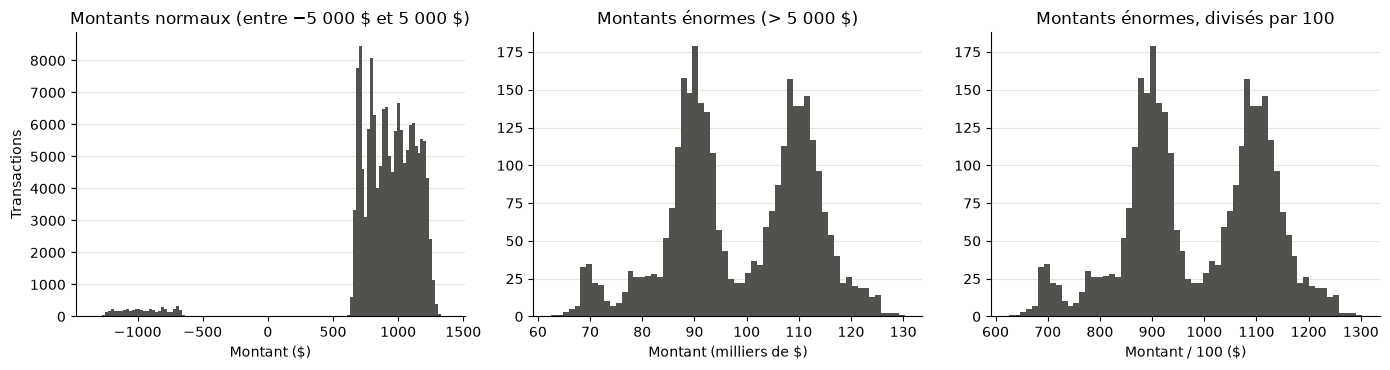

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(amount[~big], bins=120, color=GRAY)
axes[0].set_title(r"Montants normaux (entre −5 000 \$ et 5 000 \$)")
axes[0].set_xlabel(r"Montant (\$)")
axes[0].set_ylabel("Transactions")

axes[1].hist(amount[amount > 5_000] / 1_000, bins=60, color=GRAY)
axes[1].set_title(r"Montants énormes (> 5 000 \$)")
axes[1].set_xlabel(r"Montant (milliers de \$)")

axes[2].hist(amount[amount > 5_000] / 100, bins=60, color=GRAY)
axes[2].set_title("Montants énormes, divisés par 100")
axes[2].set_xlabel(r"Montant / 100 (\$)")

for ax in axes: style_ax(ax)
plt.tight_layout(); plt.show()

In [7]:
# Prix typique de chaque produit (achats normaux seulement)
normal = tx[(amount > 0) & ~big]
normal.groupby("product")["amount"].agg(["count", "median", "min", "max"]).sort_values("median").style.format("{:,.0f}")

,count,median,min,max
product,,,,
Pixel,"25,306",699,599,798
Galaxy,"25,424",799,688,909
iPhone,"24,280",899,765,"1,017"
Pixel Pro,"25,009",999,845,"1,137"
iPhone Pro,"24,255","1,099",953,"1,259"
Galaxy Ultra,"25,204","1,199",992,"1,375"


Les montants forment trois groupes :
- **Montants normaux** : chaque produit a un prix stable (Pixel ~699 \$, Galaxy ~799 \$, iPhone ~899 \$, Pixel Pro ~999 \$, iPhone Pro ~1 099 \$, Galaxy Ultra ~1 199 \$). Le plus élevé est de 1 375 \$.
- **Montants négatifs** (5 420 lignes, 3,4 %) : du même ordre de grandeur que les prix. Ce sont probablement des remboursements ou des retours (examiné à la fin de la section 3).
- **Montants énormes** (3 242 lignes, 2,1 %) : de 62 503 \$ à 130 284 \$, ce qui est impossible pour un seul téléphone. Divisés par 100, ils retombent exactement sur les prix normaux (graphique de droite). Selon moi, ce sont des **montants enregistrés en cents au lieu de dollars**. Deux autres indices vont dans le même sens : ce sont tous des nombres entiers (comme des cents), et aucun montant ne se situe entre 1 376 \$ et 62 503 \$. Ils touchent surtout **Apple** (~5 % de ses transactions, contre moins de 1 % pour les autres).

### 2.3 Doublons

In [8]:
same_key = tx.duplicated(["user", "date", "product"], keep=False)
groups = tx[same_key].groupby(["user", "date", "product"])["amount"]

print(f"Lignes copiées à l'identique                          : {tx.duplicated().sum()}")
print(f"Transactions répétant utilisateur + date + produit    : {tx.duplicated(['user', 'date', 'product']).sum()}")
print(f"  groupes où les montants sont identiques             : {(groups.nunique() == 1).sum()}")
print(f"Transactions par utilisateur, en moyenne              : {len(tx) / tx['user'].nunique():.0f}")

Lignes copiées à l'identique                          : 0
Transactions répétant utilisateur + date + produit    : 837
  groupes où les montants sont identiques             : 0
Transactions par utilisateur, en moyenne              : 63


Aucune ligne n'est copiée à l'identique. 837 transactions ont le même utilisateur, la même date et le même produit qu'une autre, mais leurs montants sont toujours différents : ce ne sont pas des copies. Avec 2 500 personnes qui font en moyenne 63 achats en 3 ans, quelques achats du même produit le même jour sont plausibles. **On les garde** (confirmé à la section 4.3).

### 2.4 Composition du panel et saisonnalité

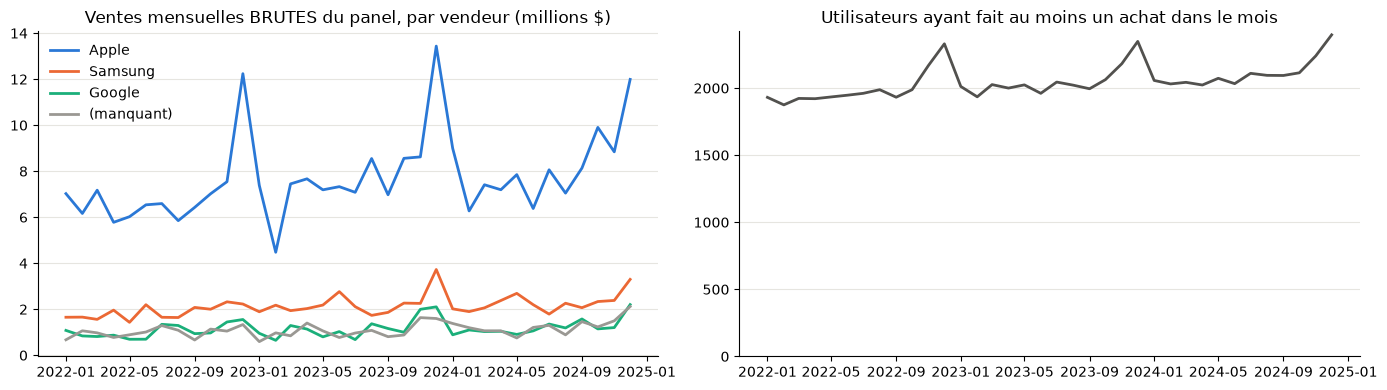

Trimestre du premier achat de chaque utilisateur :
date
2022Q1    2460
2022Q2      39
2022Q3       1
Freq: Q-DEC

Utilisateurs actifs en 2024-12 : 2,397 sur 2,500


In [9]:
month = tx["date"].dt.to_period("M")
monthly = tx.groupby([month, tx["vendor"].fillna("(manquant)")])["amount"].sum().unstack()
active_users = tx.groupby(month)["user"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for v in ["Apple", "Samsung", "Google", "(manquant)"]:
    axes[0].plot(monthly.index.to_timestamp(), monthly[v] / 1e6, color=COLORS[v], linewidth=2, label=v)
axes[0].set_title(r"Ventes mensuelles BRUTES du panel, par vendeur (millions \$)")
axes[0].legend(frameon=False)
axes[1].plot(active_users.index.to_timestamp(), active_users, color=GRAY, linewidth=2)
axes[1].set_title("Utilisateurs ayant fait au moins un achat dans le mois")
axes[1].set_ylim(0, None)
for ax in axes: style_ax(ax)
plt.tight_layout(); plt.show()

first_seen = tx.groupby("user")["date"].min().dt.to_period("Q").value_counts().sort_index()
print("Trimestre du premier achat de chaque utilisateur :")
print(first_seen.to_string())
print(f"\nUtilisateurs actifs en {month.max()} : {active_users.iloc[-1]:,} sur {tx['user'].nunique():,}")

- **Le panel est fixe** : 2 460 des 2 500 personnes font leur premier achat dès le premier trimestre 2022, les 40 autres dans les deux trimestres suivants, et 96 % sont encore actives en décembre 2024. La croissance des ventes vient donc de la consommation, pas de l'ajout de nouvelles personnes. Aucun ajustement pour la taille du panel n'est nécessaire.
- **Saisonnalité** : un pic chaque année en novembre–décembre (les Fêtes). Les revenus publiés ont aussi un Q4 beaucoup plus fort.
- **Les ventes brutes d'Apple ont des pics isolés**, causés par les montants en cents.

### 2.5 Bilan de l'inspection

| Constat | Ampleur | Décision | Vérifiée en |
|---|---|---|---|
| Vendeur manquant | 15 % des lignes (36 % des Pixel) | Déduire le vendeur du produit | 4.3 et 6.1 |
| Montants en cents | 2,1 % des lignes (~5 % chez Apple) | Diviser par 100 | 4.3 et 6.1 |
| Montants négatifs | 3,4 % des lignes | Les garder : le revenu publié est net | 4.3 et 6.1 |
| Doublons apparents | 837 transactions | Les garder : montants différents | 4.3 et 6.1 |
| Pic des Fêtes (Q4) | chaque année | La méthode doit le reproduire | 4.1 |
| Panel fixe | 2 500 personnes | Aucun ajustement nécessaire | — |

## 3. Nettoyage

Deux corrections, et deux types de lignes gardés tels quels :
1. **Vendeur manquant → déduit du produit.** On vérifie aussi que la règle est juste : sur les 134 348 lignes où le vendeur est indiqué, il correspond toujours au produit.
2. **Montants en cents → divisés par 100.** Le seuil de 5 000 \$ est sans risque : aucun montant ne se situe entre 1 376 \$ et 62 503 \$, donc tout seuil dans cet intervalle donne le même résultat (vérifié en 6.1 avec 2 000 \$ et 10 000 \$).
3. **Montants négatifs → gardés.** On suppose que le revenu publié est un revenu net, dont ces montants se soustraient (confirmé en section 4.3). Leur nature exacte est examinée à la fin de cette section.
4. **Doublons apparents → gardés.** Leurs montants sont tous différents, donc ce ne sont pas des copies (confirmé en section 4.3).

In [10]:
clean = tx.copy()

# Correction 1 : vendeur déduit du produit
clean["company"] = clean["product"].map(PRODUCT_TO_COMPANY)
known = clean["vendor"].notna()
assert (clean.loc[known, "vendor"] == clean.loc[known, "company"]).all()   # aucune contradiction

# Correction 2 : montants en cents divisés par 100
in_cents = clean["amount"].abs() > 5_000
clean["amount_clean"] = np.where(in_cents, clean["amount"] / 100, clean["amount"])

print(f"Vendeurs déduits du produit : {(~known).sum():,}")
print(f"Montants divisés par 100    : {in_cents.sum():,}")
print(f"Montants après nettoyage    : de {clean['amount_clean'].min():,.2f} $ à {clean['amount_clean'].max():,.2f} $")

Vendeurs déduits du produit : 23,683
Montants divisés par 100    : 3,242
Montants après nettoyage    : de -1,339.94 $ à 1,375.20 $


In [11]:
# Ventes totales du panel (3 ans) à chaque étape du nettoyage
steps = pd.DataFrame({
    "1. Brut": tx.groupby("vendor")["amount"].sum(),
    "2. + vendeur déduit": clean.groupby("company")["amount"].sum(),
    "3. + cents corrigés": clean.groupby("company")["amount_clean"].sum(),
}).reindex(COMPANIES) / 1e6
steps["Variation totale"] = steps["3. + cents corrigés"] / steps["1. Brut"] - 1
steps.style.format("{:,.1f}", subset=steps.columns[:3]).format("{:+.0%}", subset=["Variation totale"]) \
    .set_caption("Ventes totales du panel, 2022–2024 (millions $)")

,1. Brut,2. + vendeur déduit,3. + cents corrigés,Variation totale
Apple,277.2,289.6,49.2,-82%
Samsung,76.7,80.0,49.1,-36%
Google,41.4,65.6,41.3,-0%


- **Apple : −82 %.** Les montants en cents ne représentent qu'environ 5 % de ses transactions, mais chacun compte 100 fois : ils formaient plus des quatre cinquièmes de ses ventes brutes.
- **Samsung : −36 %.** Même problème, en plus petit.
- **Google : à peu près 0 %.** Deux effets se compensent par hasard : déduire le vendeur ajoute 58 %, puis corriger les cents en retire autant.

Sans nettoyage, Apple semblerait vendre 6,7 fois plus que Google. Après nettoyage, les trois entreprises ont des ventes de panel comparables.

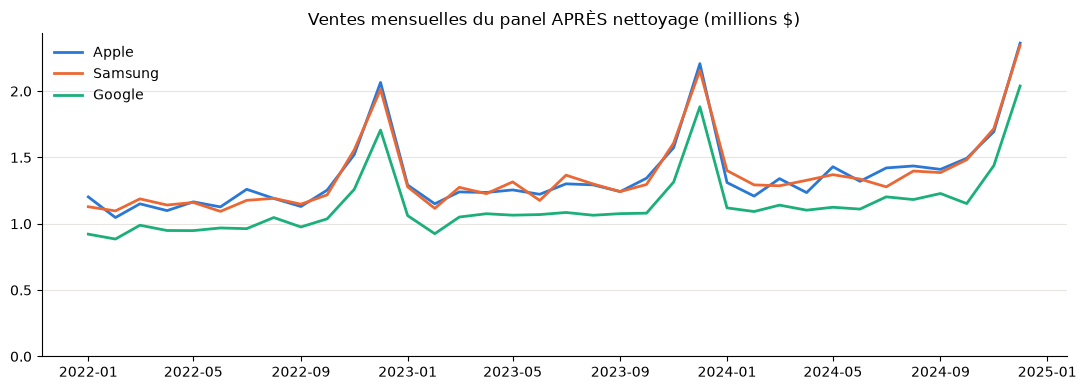

In [12]:
clean_monthly = clean.groupby([clean["date"].dt.to_period("M"), "company"])["amount_clean"].sum().unstack()

fig, ax = plt.subplots(figsize=(11, 4))
for c in COMPANIES:
    ax.plot(clean_monthly.index.to_timestamp(), clean_monthly[c] / 1e6, color=COLORS[c], linewidth=2, label=c)
ax.set_title(r"Ventes mensuelles du panel APRÈS nettoyage (millions \$)")
ax.set_ylim(0, None)
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout(); plt.show()

Après nettoyage, les trois courbes sont régulières : pic des Fêtes chaque année et légère croissance.

Apple et Samsung ont presque les mêmes ventes dans le panel, alors que le revenu publié d'Apple est environ 1,5 fois celui de Samsung. Le panel ne représente donc pas chaque entreprise dans la même proportion. **Il faudra un ratio différent pour chaque entreprise.**

### Vérification : les montants négatifs sont-ils des retours ?

Un vrai retour devrait suivre un achat du même produit par la même personne, et rembourser le prix payé. On vérifie si c'est le cas.

In [13]:
purchases = clean.loc[clean["amount_clean"] > 0, ["user", "product", "date", "amount_clean"]]

def earlier_purchases(rows):
    # Associe chaque ligne aux achats antérieurs du même produit par la même personne
    m = rows.reset_index().merge(purchases, on=["user", "product"], suffixes=("", "_achat"))
    return m[m["date_achat"] < m["date"]]

def first_half_2022(dates):
    return (dates < "2022-07-01").sum()

refunds = clean[clean["amount_clean"] < 0]
random_buys = purchases.sample(len(refunds), random_state=0)   # comparaison : des achats ordinaires
m = earlier_purchases(refunds)
matched = refunds.index.isin(m["index"])
random_matched = random_buys.index.isin(earlier_purchases(random_buys)["index"])
same_amount = (m["amount_clean"].abs().round(2) == m["amount_clean_achat"].round(2)).groupby(m["index"]).any()
min_delay = (m["date"] - m["date_achat"]).dt.days.groupby(m["index"]).min()

print("                                                   Négatifs   Achats au hasard")
print(f"Précédés d'un achat du même produit, même personne : {matched.mean():6.1%}   {random_matched.mean():6.1%}")
print(f"Sans achat antérieur                               : {(~matched).sum():6d}   {(~random_matched).sum():6d}")
print(f"  dont au 1er semestre 2022                        : {first_half_2022(refunds.loc[~matched, 'date']):6d}   {first_half_2022(random_buys.loc[~random_matched, 'date']):6d}")
print(f"\nNégatifs dont le montant égale celui d'un achat antérieur : {same_amount.mean():.1%}")
print(f"Délai médian depuis l'achat antérieur le plus récent      : {min_delay.median():.0f} jours")

                                                   Négatifs   Achats au hasard
Précédés d'un achat du même produit, même personne :  90.5%    89.6%
Sans achat antérieur                               :    515      561
  dont au 1er semestre 2022                        :    393      431

Négatifs dont le montant égale celui d'un achat antérieur : 0.1%
Délai médian depuis l'achat antérieur le plus récent      : 69 jours


**Le test ne confirme pas qu'il s'agit de retours : les montants négatifs se comportent comme des transactions ordinaires.**
- Ils sont précédés d'un achat du même produit par la même personne presque aussi souvent que des achats tirés au hasard (90,5 % contre 89,6 %). Avec 63 achats par personne en moyenne, presque tout le monde a déjà acheté chaque produit : ce rattachement ne prouve rien.
- Ceux qui n'ont pas d'achat antérieur se concentrent au début des données (393 sur 515 au premier semestre 2022), mais c'est aussi le cas des achats tirés au hasard (431 sur 561) : au début des données, personne n'a encore d'historique. Ce motif ne prouve donc rien non plus.
- Leur montant n'égale presque jamais celui d'un achat antérieur (0,1 %), alors qu'un vrai retour rembourserait le prix payé. Le délai depuis l'achat le plus récent est de 69 jours en médiane, ce qui est long pour un retour ; et c'est un minimum, puisque l'achat retourné pourrait être plus ancien.

On ne sait donc pas ce que représentent exactement ces montants. **La décision de les garder ne repose pas sur cette interprétation**, mais sur la section 4.3 : le revenu publié n'est exactement proportionnel aux ventes du panel que si on les garde.

## 4. Relier le panel aux revenus publiés

L'idée de base est une **règle de trois**. Si le panel représente toujours la même fraction des ventes d'une entreprise, alors :

$$\text{revenu} \approx \text{ventes du panel} \times \text{ratio}$$

Il faut donc vérifier que le ratio est stable dans le temps, et en particulier qu'il ne change ni avec les saisons ni avec la croissance. Cette section n'utilise que les 10 trimestres publiés (2022Q1 à 2024Q2).

### 4.1 Le ratio est-il stable ?

In [14]:
panel_q = panel_from(clean, "amount_clean", "company")   # ventes nettoyées du panel, 12 trimestres
ratio = revenue_q / panel_q.loc[TRAIN]                  # 10 trimestres publiés

view = ratio.copy()
view.index = view.index.astype(str)
view.style.format("{:,.0f}").set_caption("Ratio = revenu publié ÷ ventes du panel")

company,Apple,Samsung,Google
period,,,
2022Q1,"19,722","13,235","11,858"
2022Q2,"19,722","13,235","11,858"
2022Q3,"19,722","13,235","11,858"
2022Q4,"19,722","13,235","11,858"
2023Q1,"19,994","13,132","11,974"
2023Q2,"19,788","13,046","11,872"
2023Q3,"19,848","13,102","11,709"
2023Q4,"19,885","13,278","12,014"
2024Q1,"19,688","13,265","11,847"


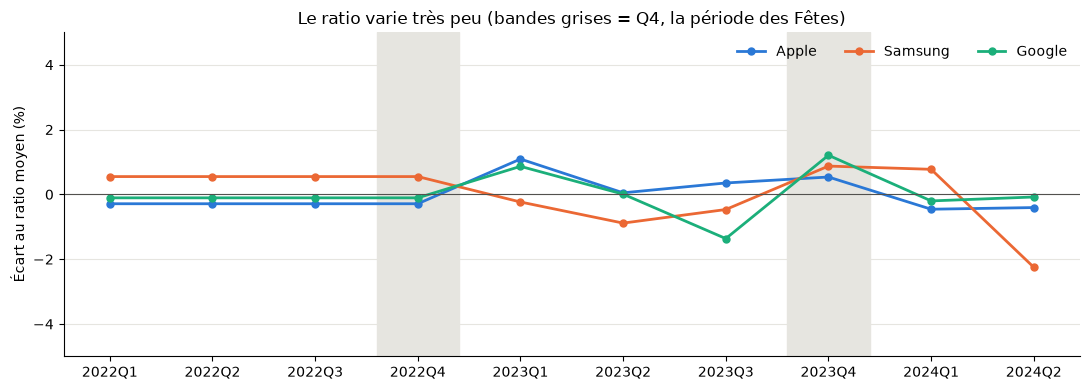

In [15]:
deviation = (ratio / ratio.mean() - 1) * 100   # écart de chaque trimestre au ratio moyen, en %

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(TRAIN))
for xi in x[TRAIN.quarter == 4]:
    ax.axvspan(xi - 0.4, xi + 0.4, color="#e6e5e0", zorder=0)
for c in COMPANIES:
    ax.plot(x, deviation[c], color=COLORS[c], linewidth=2, marker="o", markersize=5, label=c)
ax.axhline(0, color=GRAY, linewidth=0.8)
ax.set_xticks(x, TRAIN.astype(str))
ax.set_ylim(-5, 5)
ax.set_ylabel("Écart au ratio moyen (%)")
ax.set_title("Le ratio varie très peu (bandes grises = Q4, la période des Fêtes)")
ax.legend(frameon=False, ncol=3)
style_ax(ax)
plt.tight_layout(); plt.show()

In [16]:
t = np.arange(len(ratio))
stability = pd.DataFrame({
    "Ratio moyen": ratio.mean(),
    "Variation typique (%)": 100 * ratio.std() / ratio.mean(),
    "Plus grand écart (%)": deviation.abs().max(),
    "Écart moyen en Q4 (%)": deviation[TRAIN.quarter == 4].mean(),
    "Tendance (% par an)": [100 * 4 * np.polyfit(t, ratio[c], 1)[0] / ratio[c].mean() for c in COMPANIES],
})
q3_to_q4 = 100 * panel_q.loc[TRAIN].pct_change()[TRAIN.quarter == 4]
print(f"Pour comparaison, hausse des ventes du panel entre Q3 et Q4 : de {q3_to_q4.min().min():.0f} % à {q3_to_q4.max().max():.0f} %")
stability.style.format("{:,.2f}").format("{:,.0f}", subset=["Ratio moyen"])

Pour comparaison, hausse des ventes du panel entre Q3 et Q4 : de 29 % à 36 %


,Ratio moyen,Variation typique (%),Plus grand écart (%),Écart moyen en Q4 (%),Tendance (% par an)
company,,,,,
Apple,"19,779",0.51,1.09,0.12,0.07
Samsung,"13,163",0.98,2.25,0.71,-0.62
Google,"11,871",0.68,1.36,0.55,0.04


**Le ratio est presque constant.** Sa variation typique est inférieure à 1 % et son plus grand écart est de 2,25 % (Samsung, 2024Q2).
- **Effet des Fêtes négligeable** : en Q4, le ratio n'est que 0,1 à 0,7 % au-dessus de sa moyenne, alors que les ventes du panel bondissent de 29 à 36 % entre Q3 et Q4. Avec seulement deux Q4 dans les données, on ne peut pas exclure un très petit effet, mais il serait sans importance à côté de ce bond.
- **Tendance négligeable** : moins de 1 % par an.

Autrement dit, **la saisonnalité et la croissance sont déjà dans les ventes du panel**. Le ratio sert seulement à passer de l'échelle du panel (quelques millions de dollars) à celle de l'entreprise (des dizaines de milliards).

Le ratio est très différent d'une entreprise à l'autre (~19 800 pour Apple, ~13 200 pour Samsung, ~11 900 pour Google) : le panel sous-représente Apple par rapport aux deux autres.

### 4.2 Le panel suit-il la croissance d'une année à l'autre ?

On compare chaque trimestre au même trimestre de l'année précédente (par exemple 2023Q3 contre 2022Q3). Ça élimine l'effet des saisons et ne laisse que la croissance.

Plus grand écart entre la croissance du panel et celle du revenu : 1.6 points


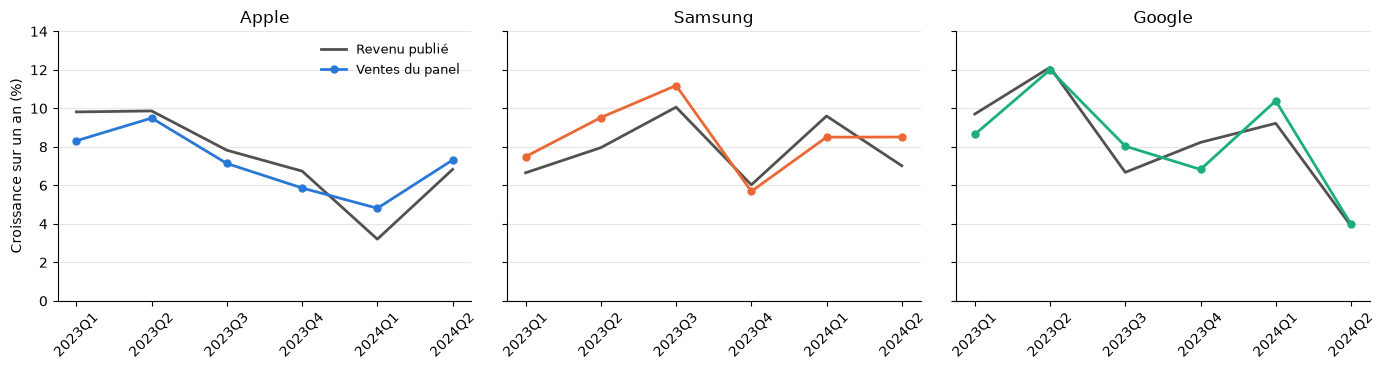

In [17]:
yoy_panel = 100 * panel_q.loc[TRAIN].pct_change(4)
yoy_revenue = 100 * revenue_q.pct_change(4)
print(f"Plus grand écart entre la croissance du panel et celle du revenu : {(yoy_panel - yoy_revenue).abs().max().max():.1f} points")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
x = TRAIN[4:].astype(str)
for ax, c in zip(axes, COMPANIES):
    ax.plot(x, yoy_revenue[c].iloc[4:], color=GRAY, linewidth=2, label="Revenu publié")
    ax.plot(x, yoy_panel[c].iloc[4:], color=COLORS[c], linewidth=2, marker="o", markersize=5, label="Ventes du panel")
    ax.set_title(c)
    ax.tick_params(axis="x", labelrotation=45)
    style_ax(ax)
axes[0].set_ylim(0, 14)
axes[0].set_ylabel("Croissance sur un an (%)")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

La croissance du panel suit celle du revenu à moins de 2 points près. Le panel capte donc aussi la **tendance**, pas seulement le pic des Fêtes. C'est ce qui justifie la méthode B de la section 5.

### 4.3 Vérification du nettoyage avec les données de 2022

En 2022, le ratio est **exactement** le même pour les quatre trimestres (variation de 0,0000 % dans le tableau ci-dessous). Une égalité aussi parfaite ne peut pas être une coïncidence : les revenus de cet exercice ont vraisemblablement été fabriqués à partir des « vraies » ventes du panel, multipliées par un facteur propre à chaque entreprise (avec un peu de bruit à partir de 2023).

Ça donne un test très puissant : **si une de mes corrections était fausse, l'égalité serait brisée.** On retire donc chaque correction, une à la fois, et on mesure la variation du ratio en 2022. Ce test n'utilise aucun des trimestres à prédire.

In [18]:
# Chaque variante retire UNE décision du nettoyage
variants = {
    "Nettoyage retenu": panel_q,
    "Doublons supprimés": panel_from(clean.drop_duplicates(["user", "date", "product"]), "amount_clean", "company"),
    "Montants négatifs exclus": panel_from(clean[clean["amount_clean"] > 0], "amount_clean", "company"),
    "Vendeur non déduit": panel_from(clean[clean["vendor"].notna()], "amount_clean", "vendor"),
    "Cents non corrigés": panel_from(clean, "amount", "company"),
}
Y2022 = TRAIN[TRAIN.year == 2022]

def ratio_variation_2022(panel):
    """Variation typique (%) du ratio revenu / panel sur les 4 trimestres de 2022."""
    r = revenue_q.loc[Y2022] / panel.loc[Y2022]
    return 100 * r.std() / r.mean()

pd.DataFrame({name: ratio_variation_2022(p) for name, p in variants.items()}).T \
    .style.format("{:.4f} %").set_caption("Variation du ratio en 2022 (0 = égalité parfaite)")

company,Apple,Samsung,Google
Nettoyage retenu,0.0000 %,0.0000 %,0.0000 %
Doublons supprimés,0.1882 %,0.1422 %,0.1639 %
Montants négatifs exclus,0.2557 %,0.4794 %,0.6369 %
Vendeur non déduit,0.3143 %,0.3904 %,1.9641 %
Cents non corrigés,4.8032 %,7.9313 %,11.6920 %


**Seul le nettoyage retenu donne une égalité parfaite** (variation nulle). Retirer n'importe quelle décision la brise :
- **Cents non corrigés** : 5 à 12 % de variation. C'est de loin l'erreur la plus grave.
- **Vendeur non déduit** : jusqu'à 2 % pour Google. Le revenu inclut donc bien les transactions sans vendeur.
- **Montants négatifs exclus** : 0,3 à 0,6 %. Le revenu est bien **net** des montants négatifs.
- **Doublons supprimés** : 0,1 à 0,2 %. Ce sont bien de vrais achats.

Chaque décision de la section 3 est donc confirmée **avant** de regarder les trimestres à prédire. Avec des données réelles, on n'aurait jamais une égalité aussi parfaite, mais l'idée reste utile : un nettoyage correct devrait rendre la relation entre le panel et le revenu plus stable, ce qui donne un moyen de le vérifier.

## 5. Estimer le revenu

### 5.1 Trois méthodes

Chaque méthode est appliquée séparément à chaque entreprise. On note *T* le trimestre à estimer et *T − 4* le même trimestre un an plus tôt.

| Méthode | Calcul | Idée |
|---|---|---|
| **A. Ratio moyen** | ventes du panel en *T* × ratio moyen du passé | La règle de trois de la section 4.1 |
| **B. An passé × croissance** | revenu en *T − 4* × (ventes du panel en *T* ÷ ventes du panel en *T − 4*) | Le **pic des Fêtes** vient du même trimestre l'an passé ; la **croissance** vient du panel (section 4.2) |
| C. Sans panel (référence) | revenu en *T − 4* × croissance annuelle moyenne passée (0 % s'il n'y a pas encore d'historique) | N'utilise **pas** les transactions. Sert à mesurer ce que le panel apporte |

**Méthode retenue : la moyenne de A et B.** B revient en fait à multiplier les ventes du panel par le ratio du même trimestre l'an passé, puisque revenu(*T − 4*) ÷ ventes(*T − 4*) est ce ratio. A et B supposent donc toutes les deux que le ratio est stable, mais l'estiment différemment :
- **A** fait la moyenne de tous les trimestres passés : elle est peu sensible au bruit d'un trimestre isolé, mais réagirait lentement si le ratio se mettait à changer ;
- **B** n'utilise que le même trimestre de l'an passé : elle suivrait mieux un ratio qui change ou qui varie selon la saison, mais elle dépend du bruit de ce seul trimestre.

En faire la moyenne équilibre ces deux défauts.

In [19]:
MODELS = ["A. Ratio moyen", "B. An passé × croissance", "C. Sans panel (référence)", "Final (moyenne A et B)"]

def predict(model, company, target, history, panel=None):
    """Estime le revenu de `company` au trimestre `target`, en n'utilisant que les revenus des trimestres `history`.
    `panel` permet de tester une autre version des données (section 6.1) ; par défaut, le panel nettoyé."""
    panel = panel_q if panel is None else panel
    R, P = revenue_q[company], panel[company]
    last_year = target - 4
    if model == MODELS[0]:
        return P[target] * (R[history] / P[history]).mean()
    if model == MODELS[1]:
        return R[last_year] * P[target] / P[last_year]
    if model == MODELS[2]:
        yearly_growth = (R[history] / R[history].shift(4)).dropna()
        return R[last_year] * (yearly_growth.mean() if len(yearly_growth) else 1.0)
    if model == MODELS[3]:
        return (predict(MODELS[0], company, target, history, panel) + predict(MODELS[1], company, target, history, panel)) / 2
    raise ValueError(model)

### 5.2 Tester les méthodes sur le passé (backtest)

Pour chaque trimestre de 2023Q1 à 2024Q2, on fait comme si on était juste avant : on n'utilise **que les trimestres précédents** pour estimer, puis on compare au vrai revenu. On obtient 6 trimestres × 3 entreprises = 18 tests par méthode. (2022 ne peut pas servir de test, car les méthodes B et C ont besoin de l'année précédente.)

In [20]:
rows = []
for i, target in enumerate(TRAIN):
    if i < 4:                 # il faut au moins un an d'historique
        continue
    history = TRAIN[:i]       # seulement les trimestres précédents
    for company in COMPANIES:
        actual = revenue_q.loc[target, company]
        for model in MODELS:
            pred = predict(model, company, target, history)
            rows.append({"période": str(target), "entreprise": company, "modèle": model,
                         "erreur (%)": 100 * (pred / actual - 1)})
backtest = pd.DataFrame(rows)

backtest["erreur absolue"] = backtest["erreur (%)"].abs()
backtest_table = backtest.pivot_table(index="modèle", columns="entreprise", values="erreur absolue")[COMPANIES]
backtest_table["Moyenne"] = backtest.groupby("modèle")["erreur absolue"].mean()
backtest_table["Biais"] = backtest.groupby("modèle")["erreur (%)"].mean()
backtest_table.loc[MODELS].style.format("{:.2f} %") \
    .set_caption("Backtest 2023Q1–2024Q2 : erreur moyenne (biais = erreur moyenne en gardant le signe)")

entreprise,Apple,Samsung,Google,Moyenne,Biais
modèle,,,,,
A. Ratio moyen,0.55 %,1.11 %,0.69 %,0.78 %,0.13 %
B. An passé × croissance,0.86 %,1.00 %,0.80 %,0.89 %,0.12 %
C. Sans panel (référence),3.16 %,2.46 %,3.55 %,3.05 %,-0.47 %
Final (moyenne A et B),0.71 %,1.05 %,0.73 %,0.83 %,0.12 %


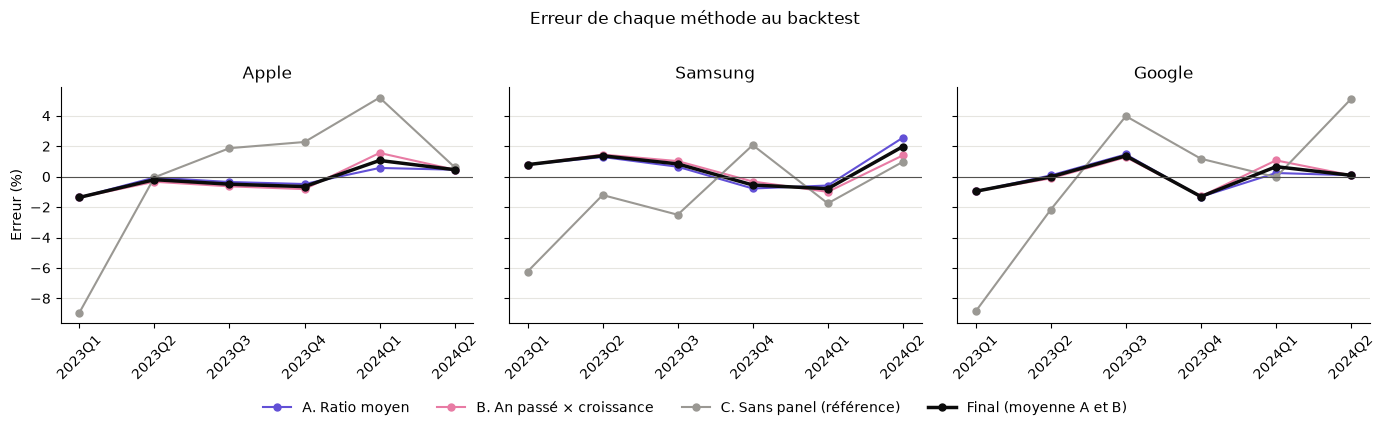

In [21]:
model_colors = {MODELS[0]: "#6250d6", MODELS[1]: "#e87ba4", MODELS[2]: "#9a9893", MODELS[3]: "#0b0b0b"}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, company in zip(axes, COMPANIES):
    sub = backtest[backtest["entreprise"] == company]
    for model in MODELS:
        s = sub[sub["modèle"] == model]
        ax.plot(s["période"], s["erreur (%)"], color=model_colors[model], marker="o", markersize=5,
                linewidth=2.5 if model == MODELS[3] else 1.5, label=model)
    ax.axhline(0, color=GRAY, linewidth=0.8)
    ax.set_title(company)
    ax.tick_params(axis="x", labelrotation=45)
    style_ax(ax)
axes[0].set_ylabel("Erreur (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Erreur de chaque méthode au backtest", y=1.02)
plt.tight_layout(); plt.show()

- **A et B se trompent en moyenne de moins de 1 %** (0,78 % et 0,89 %). **C**, qui n'utilise pas les transactions, se trompe de 3,05 %, soit presque 4 fois plus. Le panel apporte donc une vraie information : il mesure la croissance de chaque trimestre, alors que C suppose une croissance toujours égale à la moyenne passée.
- A et B font des erreurs très semblables, car les deux multiplient les ventes du panel par un ratio passé : quand le panel s'écarte du revenu un trimestre donné, les deux se trompent dans le même sens.
- La moyenne de A et B (0,83 %) se situe entre les deux.
- Pas de biais : en moyenne, on ne surestime ni ne sous-estime (+0,1 %).

### 5.3 Estimations pour Q3 et Q4 2024

On applique chaque méthode avec les 10 trimestres publiés, puis on utilise les ventes du panel de Q3 et Q4 2024.

**Intervalle d'incertitude :** on mesure l'erreur type de la méthode retenue sur les 18 tests du backtest (racine de la moyenne des erreurs au carré), puis on prend ± 2 erreurs types. Si les erreurs suivent à peu près une loi normale, cela correspond à environ 95 % de confiance ; avec seulement 18 tests, c'est une approximation.

In [22]:
forecast = pd.DataFrame([
    {"période": str(t), "entreprise": c, "modèle": m, "prévision": predict(m, c, t, TRAIN)}
    for t in TEST_PERIODS for c in COMPANIES for m in MODELS
])
final_forecast = (forecast[forecast["modèle"] == MODELS[3]]
                  .pivot(index="période", columns="entreprise", values="prévision")[COMPANIES])

final_errors = backtest.loc[backtest["modèle"] == MODELS[3], "erreur (%)"] / 100
RMSE = np.sqrt((final_errors ** 2).mean())
print(f"Erreur type au backtest : {RMSE:.2%}  ->  intervalle de ± {2 * RMSE:.2%}")

est = final_forecast.stack()
final_table = pd.DataFrame({
    "Bas (G$)": est / (1 + 2 * RMSE) / 1e9,      # erreur = estimation / réel − 1, donc réel = estimation / (1 + erreur)
    "Estimation (G$)": est / 1e9,
    "Haut (G$)": est / (1 - 2 * RMSE) / 1e9,
}).swaplevel().sort_index().reindex(COMPANIES, level=0)
final_table.style.format("{:,.2f}").set_caption("Revenu estimé pour Q3–Q4 2024 (milliards $)")

Erreur type au backtest : 0.97%  ->  intervalle de ± 1.94%


## 6. Comparaison avec les vrais revenus de Q3–Q4 2024

Les estimations de la section 5.3 sont maintenant figées. On charge pour la première fois le fichier complet, qui contient les vrais revenus de Q3–Q4 2024.

In [23]:
EVAL_AVAILABLE = os.path.exists(ACTUALS_PATH)

if EVAL_AVAILABLE:
    actuals = pd.read_csv(ACTUALS_PATH)
    actuals["period"] = quarter_period(actuals)
    revenue_full = actuals.pivot(index="period", columns="company", values="revenue")[COMPANIES]
    # Vérification : le fichier complet doit être identique au fichier masqué sur les 10 trimestres communs
    assert np.allclose(revenue_full.loc[TRAIN], revenue_q.loc[TRAIN])
    print(f"Fichier complet chargé : de {revenue_full.index.min()} à {revenue_full.index.max()}, identique au fichier masqué sur {len(TRAIN)} trimestres")
else:
    print(f"Fichier {ACTUALS_PATH} introuvable : la section 6 est sautée. Les estimations de la section 5.3 restent valides.")

Fichier complet chargé : de 2022Q1 à 2024Q4, identique au fichier masqué sur 10 trimestres


In [24]:
if EVAL_AVAILABLE:
    actual_test = revenue_full.loc[TEST_PERIODS, COMPANIES]
    actual_test.index = actual_test.index.astype(str)

    final_eval = final_table.copy()
    final_eval["Réel (G$)"] = actual_test.stack().swaplevel() / 1e9
    final_eval["Erreur (%)"] = 100 * (final_eval["Estimation (G$)"] / final_eval["Réel (G$)"] - 1)
    final_eval["Dans l'intervalle"] = final_eval["Réel (G$)"].between(final_eval["Bas (G$)"], final_eval["Haut (G$)"]).map({True: "oui", False: "non"})
    display(final_eval.style
            .format("{:,.2f}", subset=["Bas (G$)", "Estimation (G$)", "Haut (G$)", "Réel (G$)"])
            .format("{:+.2f} %", subset=["Erreur (%)"])
            .set_caption("Méthode retenue : estimation vs réel"))

In [25]:
if EVAL_AVAILABLE:
    forecast["réel"] = [revenue_full.loc[pd.Period(p), c] for p, c in zip(forecast["période"], forecast["entreprise"])]
    forecast["erreur absolue"] = 100 * (forecast["prévision"] / forecast["réel"] - 1).abs()
    comparison = pd.DataFrame({
        "Erreur moyenne au backtest": backtest_table["Moyenne"],
        "Erreur moyenne Q3–Q4 2024": forecast.groupby("modèle")["erreur absolue"].mean(),
        "Pire erreur Q3–Q4 2024": forecast.groupby("modèle")["erreur absolue"].max(),
    }).loc[MODELS]
    display(comparison.style.format("{:.2f} %").set_caption("Toutes les méthodes : backtest vs vrais trimestres"))

,Erreur moyenne au backtest,Erreur moyenne Q3–Q4 2024,Pire erreur Q3–Q4 2024
modèle,,,
A. Ratio moyen,0.78 %,0.68 %,1.21 %
B. An passé × croissance,0.89 %,0.46 %,1.25 %
C. Sans panel (référence),3.05 %,2.47 %,4.15 %
Final (moyenne A et B),0.83 %,0.54 %,0.72 %


- **Erreur moyenne de 0,54 %, pire erreur de 0,72 %.** C'est le bon ordre de grandeur, et même un peu mieux qu'au backtest (0,83 %) : la méthode fonctionne sur des trimestres qu'elle n'avait jamais vus.
- **Les 6 vrais revenus tombent dans l'intervalle** de ± 1,94 %, avec beaucoup de marge.
- Ici, B (0,46 %) fait mieux que A (0,68 %), l'inverse du backtest : l'écart entre les deux relève probablement du hasard. La moyenne a la plus petite **pire** erreur (0,72 %, contre environ 1,2 % pour A et B). C'est l'intérêt de ne pas tout miser sur une seule méthode.
- La méthode sans panel (C) se trompe de 2,47 % en moyenne, soit environ 4,5 fois plus.
- Pas de biais clair : Q3 est légèrement surestimé pour les trois entreprises (+0,34 à +0,54 %), mais trois erreurs du même signe arrivent une fois sur quatre par simple hasard, et en Q4 les erreurs vont dans les deux sens (Apple et Samsung sous-estimés, Google surestimé).

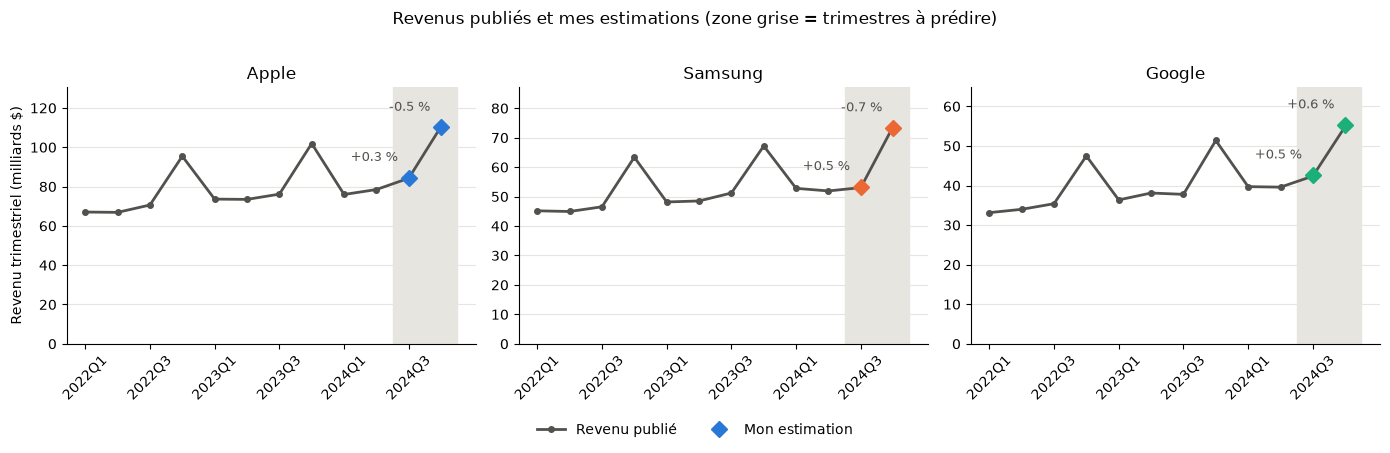

In [26]:
if EVAL_AVAILABLE:
    x_all = list(revenue_full.index.astype(str))
    test_pos = [x_all.index(str(p)) for p in TEST_PERIODS]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, company in zip(axes, COMPANIES):
        ax.plot(x_all, revenue_full[company] / 1e9, color=GRAY, linewidth=2, marker="o", markersize=4, label="Revenu publié")
        est_c = final_forecast[company] / 1e9
        ax.plot(est_c.index, est_c.values, color=COLORS[company], linestyle="none", marker="D", markersize=8, label="Mon estimation")
        for p, v in est_c.items():
            ax.annotate(f"{final_eval.loc[(company, p), 'Erreur (%)']:+.1f} %", (p, v), textcoords="offset points",
                        xytext=(-8, 12), ha="right", fontsize=9, color=GRAY)
        ax.axvspan(min(test_pos) - 0.5, max(test_pos) + 0.5, color="#e6e5e0", zorder=0)
        ax.set_title(company)
        ax.set_ylim(0, revenue_full[company].max() / 1e9 * 1.18)
        ax.set_xticks(range(0, len(x_all), 2), x_all[::2])
        ax.tick_params(axis="x", labelrotation=45)
        style_ax(ax)
    axes[0].set_ylabel(r"Revenu trimestriel (milliards \$)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.08))
    fig.suptitle("Revenus publiés et mes estimations (zone grise = trimestres à prédire)", y=1.02)
    plt.tight_layout(); plt.show()

### 6.1 Et si on avait fait d'autres choix ?

On refait exactement la même estimation de Q3–Q4 2024 en changeant **une seule** décision de nettoyage à la fois. On voit ainsi combien chaque décision compte.

In [27]:
def evaluate(panel):
    """Erreur (%) de la méthode retenue sur Q3–Q4 2024, pour une version donnée du panel."""
    return pd.Series({
        (c, str(t)): 100 * (predict(MODELS[3], c, t, TRAIN, panel) / revenue_full.loc[t, c] - 1)
        for c in COMPANIES for t in TEST_PERIODS
    })

if EVAL_AVAILABLE:
    scenarios = {
        "Nettoyage retenu": panel_q,
        "Sans correction des cents": variants["Cents non corrigés"],
        "Sans déduire le vendeur": variants["Vendeur non déduit"],
        "Montants négatifs exclus": variants["Montants négatifs exclus"],
        "Doublons supprimés": variants["Doublons supprimés"],
        "Aucune correction (données brutes)": panel_from(tx.dropna(subset=["vendor"]), "amount", "vendor"),
    }
    for threshold in [2_000, 10_000]:
        amount_alt = np.where(clean["amount"].abs() > threshold, clean["amount"] / 100, clean["amount"])
        scenarios[f"Seuil des cents à {threshold:,} $".replace(",", " ")] = panel_from(clean.assign(amount_alt=amount_alt), "amount_alt", "company")

    errors = pd.DataFrame({name: evaluate(p) for name, p in scenarios.items()}).T.abs()
    scenario_table = errors.T.groupby(level=0).mean().T[COMPANIES]
    scenario_table["Moyenne"] = errors.mean(axis=1)
    scenario_table["Pire erreur"] = errors.max(axis=1)
    display(scenario_table.style.format("{:.2f} %").set_caption("Erreur moyenne sur Q3–Q4 2024 selon les choix de nettoyage"))

,Apple,Samsung,Google,Moyenne,Pire erreur
Nettoyage retenu,0.42 %,0.63 %,0.58 %,0.54 %,0.72 %
Sans correction des cents,3.12 %,6.30 %,12.12 %,7.18 %,14.53 %
Sans déduire le vendeur,0.77 %,0.63 %,0.93 %,0.78 %,1.76 %
Montants négatifs exclus,0.30 %,0.94 %,1.16 %,0.80 %,1.77 %
Doublons supprimés,0.48 %,0.63 %,0.47 %,0.53 %,0.74 %
Aucune correction (données brutes),5.09 %,5.18 %,12.13 %,7.47 %,16.73 %
Seuil des cents à 2 000 $,0.42 %,0.63 %,0.58 %,0.54 %,0.72 %
Seuil des cents à 10 000 $,0.42 %,0.63 %,0.58 %,0.54 %,0.72 %


- **Corriger les cents est essentiel** : sans cette correction, l'erreur passe de 0,54 % à 7,18 %. Ces montants gonflent chaque trimestre d'une quantité différente, et le ratio ne peut pas compenser un bruit qui change tout le temps.
- **Déduire le vendeur aide, mais moins qu'on pourrait le croire** (0,78 % sans, contre 0,54 % avec). Google perd environ le même tiers de ses Pixel chaque trimestre ; ce manque est stable, donc le ratio de Google le compense en grande partie. **Leçon : un biais stable est absorbé par le ratio, un bruit variable ne l'est pas.**
- **Exclure les montants négatifs** dégrade l'erreur (0,80 %), ce qui confirme la section 4.3.
- **Supprimer les doublons ou changer le seuil des cents** ne change presque rien ici. Pour les doublons, c'est le test de la section 4.3 qui tranche.

## 7. Hypothèses et leur effet sur les résultats

L'énoncé demande de documenter les hypothèses et d'expliquer comment elles influencent les résultats. Le tableau les regroupe. La dernière colonne vient de la section 6.1 : erreur moyenne sur Q3–Q4 2024 si l'hypothèse était abandonnée (contre 0,54 % avec toutes les hypothèses).

| # | Hypothèse | Pourquoi on y croit | Erreur si on l'abandonne |
|---|---|---|---|
| 1 | Les montants de plus de 5 000 \$ sont en cents | Impossibles en dollars ; divisés par 100 ils tombent sur les prix normaux ; ce sont tous des entiers ; égalité parfaite de 2022 (4.3) | 7,18 % |
| 2 | Le vendeur manquant se déduit du produit | Aucun produit n'a deux vendeurs (2.1) ; égalité parfaite de 2022 (4.3) | 0,78 % |
| 3 | Les montants négatifs font partie du revenu net | Égalité parfaite de 2022 seulement si on les garde (4.3), même si on ne peut pas confirmer que ce sont des retours (fin de la section 3) | 0,80 % |
| 4 | Les doublons apparents sont de vrais achats | Montants tous différents (2.3) ; égalité parfaite de 2022 (4.3) | 0,53 % (effet négligeable) |
| 5 | Le seuil de 5 000 \$ sépare bien les deux groupes | Aucun montant entre 1 376 \$ et 62 503 \$ (2.2) | 0,54 % (aucun effet) |
| 6 | Le ratio de chaque entreprise reste stable dans le temps | Variation typique sous 1 %, effet des Fêtes et tendance négligeables (4.1) ; la croissance du panel suit celle du revenu (4.2) | Non mesurable ici. Si le ratio se mettait à dériver (par exemple parce que la composition du panel change), toutes les estimations seraient décalées ; B, qui utilise le ratio d'il y a un an, s'ajusterait plus vite que A |

## 8. Limites

- **Le panel est petit.** Environ 4 400 transactions par entreprise et par trimestre doivent représenter des dizaines de milliards de dollars : un seul téléphone acheté dans le panel « vaut » de 8 à 24 millions de dollars de revenu. Sur un vrai panel, tiré au hasard dans la population, ça créerait à lui seul une erreur d'environ 1,5 % par trimestre (1/√4 400). Mes erreurs sont plus petites parce qu'ici, le revenu a vraisemblablement été fabriqué à partir du panel lui-même (section 4.3). **Sur des données réelles, une erreur de 2 à 5 % serait déjà un bon résultat.**
- **Le panel ne représente pas le marché.** Les ratios diffèrent beaucoup entre les entreprises, peut-être à cause d'un biais géographique, d'âge ou de banque émettrice. La méthode fonctionne tant que ce biais reste stable ; elle échouerait si le panel changeait de composition.
- **Le revenu publié ne vient pas que des téléphones payés par carte.** Il inclut aussi les services, les autres appareils et les ventes aux opérateurs. On suppose que tout ça évolue au même rythme que le panel.
- **Seulement 10 trimestres d'historique**, donc des tests statistiques peu puissants.

## 9. Conclusion

Les transactions par carte de crédit permettent d'estimer le revenu trimestriel des trois entreprises **à environ 0,5 % près**, à condition de nettoyer les données. Les trois pièges (montants en cents, vendeur manquant, montants négatifs) ont été trouvés à l'inspection, traités, puis **confirmés avec les données de 2022**, avant de regarder les trimestres à prédire. Une simple règle de trois, combinée au revenu du même trimestre l'an passé, suffit ensuite, car les ventes du panel contiennent déjà le pic des Fêtes et la croissance.

In [28]:
if EVAL_AVAILABLE:
    display(final_eval[["Bas (G$)", "Estimation (G$)", "Haut (G$)", "Réel (G$)", "Erreur (%)"]].style
            .format("{:,.2f}", subset=["Bas (G$)", "Estimation (G$)", "Haut (G$)", "Réel (G$)"])
            .format("{:+.2f} %", subset=["Erreur (%)"])
            .set_caption(f"Résultat final — erreur moyenne : {final_eval['Erreur (%)'].abs().mean():.2f} %"))
else:
    display(final_table.style.format("{:,.2f}").set_caption("Revenu estimé pour Q3–Q4 2024 (milliards $)"))